# 05 · Putting the model to work: choosing candidates under a daily capacity limit

**Series:** Exploring the ZTF Bright Transient Survey to find Type Ia supernovae
1. Loading & cleaning with pandas
2. Visualising with matplotlib & seaborn
3. Finding patterns & a first Ia classifier
4. Experimenting with models
5. **Working under a capacity limit** ← you are here

---

Notebooks 3 and 4 asked *how good* the classifier is. This one asks how to **use** it when resources are limited. A hypothetical operational scenario:

* About **10,000 candidates arrive per month**. Treat this dataset as one month of alerts: that's about **333 a day**.
* The follow-up team can take **100 spectra a day**.
* **At most 10** of those 100 may turn out *not* to be Ia (false positives).

Questions:
1. **Can the model meet this, and how do we check it honestly?** The limit applies to *every day*, so an average isn't enough.
2. **Which decision rule?** Take the top 100? Use a probability threshold? Something smarter?
3. **What would break it?** The Ia fraction of the incoming stream, and drift over time.
4. **How do we notice when it breaks?**

The key idea: **you don't tune a model to hit a precision.** The model *ranks* candidates. Precision and volume come from the **decision rule** applied to that ranking, and that rule is what we design and test here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import precision_recall_curve

import ztf_style
from ztf_style import IA, INK, INK_2, MUTED, GRID

ztf_style.use()
df = pd.read_parquet("data/bts_clean.parquet")

PER_DAY = 333     # candidates arriving per day (~10,000 a month)
CAPACITY = 100    # spectra the team can take per day
MAX_FP = 10       # most false positives allowed per day

## 0 · Setup: data, model and two honest test sets

The features and split are the same as in notebooks 3 and 4. The model is gradient boosting with the settings tuned in notebook 4. (Tuned XGBoost, LightGBM or the neural network would do almost exactly as well.)

Every rule is checked in two settings:
* **random split:** trained on the training set, scored on the test set from notebooks 3 and 4;
* **future years:** trained on 2018–2023, scored on 2024–2025. This is the stricter test: notebook 3 found that the data changed in 2022.

In [2]:
before_2026 = df["discdate"] < "2026-01-01"
labelled = df[df["class3"].notna() & before_2026].copy()
unlabelled = df[df["class3"].isna() & before_2026].copy()


def add_features(d):
    d = d.copy()
    for col in ["rise", "fade", "duration"]:
        d[f"log_{col}"] = np.log10(d[col] + 1)
    d["abs_b"] = d["b"].abs()
    d["peak_in_g"] = (d["peakfilt"] == "g").astype(int)
    for col in ["rise_is_limit", "fade_is_limit", "duration_is_limit"]:
        d[col] = d[col].astype(int)
    return d


labelled, unlabelled = add_features(labelled), add_features(unlabelled)
y = labelled["is_ia"].astype(bool).astype(int)
PHOTOMETRIC = ["peakmag", "log_rise", "log_fade", "log_duration",
               "rise_is_limit", "fade_is_limit", "duration_is_limit",
               "peak_in_g", "abs_b", "A_V"]

X = labelled[PHOTOMETRIC]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
past = labelled["discdate"] < "2024-01-01"


def make_model():
    # Settings tuned in notebook 4, section 4
    return HistGradientBoostingClassifier(learning_rate=0.1, max_leaf_nodes=7, min_samples_leaf=100, random_state=0)


# each scenario: (training features, training labels, evaluation features, evaluation labels)
scenarios = {
    "random split": (X_train, y_train, X_test, y_test),
    "future years": (labelled.loc[past, PHOTOMETRIC], y[past], labelled.loc[~past, PHOTOMETRIC], y[~past]),
}
proba, truth = {}, {}
for name, (Xtr, ytr, Xev, yev) in scenarios.items():
    proba[name] = make_model().fit(Xtr, ytr).predict_proba(Xev)[:, 1]
    truth[name] = yev.to_numpy()
    print(f"{name:13s}: {len(Xtr):,} training objects, {len(Xev):,} evaluation objects ({yev.mean():.0%} Ia)")

random split : 5,874 training objects, 1,958 evaluation objects (68% Ia)
future years : 6,041 training objects, 1,791 evaluation objects (73% Ia)


## 1 · Turning the requirement into a number

Sending 100 of 333 means sending the **top 30%** of each day's candidates. Allowing 10 false positives in 100 means that top 30% must be **at least 90% Ia**.

So the question is: *how pure is the top 30% of the model's ranking?* Sort the evaluation objects from most to least Ia-like, then work down the list and track the precision of everything sent so far:

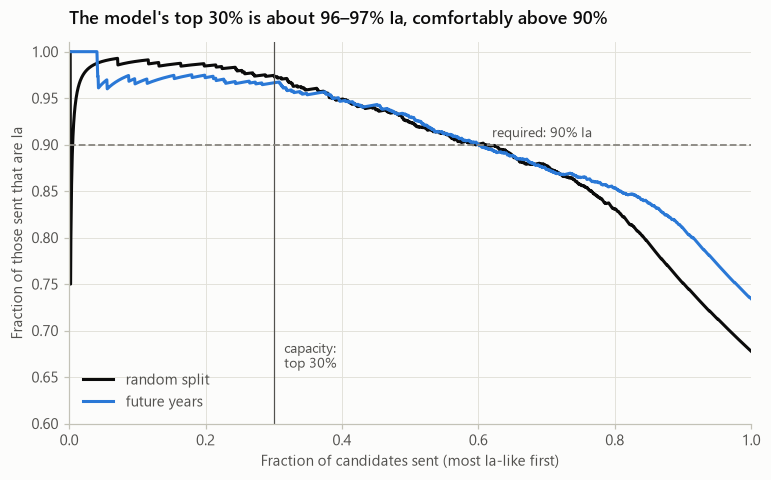

In [3]:
fig, ax = plt.subplots()
for (name, p), color in zip(proba.items(), [INK, IA]):
    hits = truth[name][np.argsort(-p)]                  # 1 = Ia, in order of decreasing P(Ia)
    n_sent = np.arange(1, len(p) + 1)
    ax.plot(n_sent / len(p), np.cumsum(hits) / n_sent, color=color, label=name)
ax.axvline(CAPACITY / PER_DAY, color=INK_2, linewidth=0.8)
ax.axhline(1 - MAX_FP / CAPACITY, color=MUTED, linewidth=1.2, linestyle="--")
ax.annotate("capacity:\ntop 30%", xy=(CAPACITY / PER_DAY + 0.015, 0.66), color=INK_2, fontsize=9)
ax.annotate("required: 90% Ia", xy=(0.62, 1 - MAX_FP / CAPACITY + 0.008), color=INK_2, fontsize=9)
ax.set(xlabel="Fraction of candidates sent (most Ia-like first)", ylabel="Fraction of those sent that are Ia",
       xlim=(0, 1), ylim=(0.6, 1.01))
ax.legend(loc="lower left")
ax.set_title("The model's top 30% is about 96–97% Ia, comfortably above 90%")
ztf_style.save(fig, "05_precision_at_top");

This is reassuring, but it's a **whole-set average**. The limit applies to *every day*, and each day's 333 candidates are a different random mix: some days have more hard cases than others. We need the **distribution of daily false positives**, and especially the bad days.

## 2 · Simulating days

To get that distribution, we **simulate** many days. Each simulated day draws 333 objects at random (with replacement) from an evaluation set, ranks them by the model's P(Ia), and applies a **decision rule** that says how many to send. Because we know the true classes, we can count each day's false positives.

A decision rule ("policy") is just a function: it receives that day's probabilities, sorted from highest to lowest, and returns how many candidates to send.

In [4]:
def draw_day(rng, p, truth, ia_fraction=None):
    # One day of PER_DAY candidates, returned as row positions sorted most Ia-like first.
    # With ia_fraction set, the day's Ia / non-Ia mix is controlled (used in section 3).
    if ia_fraction is None:
        day = rng.integers(0, len(p), PER_DAY)
    else:
        n_ia = rng.binomial(PER_DAY, ia_fraction)
        day = np.concatenate([rng.choice(np.flatnonzero(truth == 1), n_ia),
                              rng.choice(np.flatnonzero(truth == 0), PER_DAY - n_ia)])
    return day[np.argsort(-p[day])]


def simulate_days(p, truth, policy, ia_fraction=None, n_days=5000, seed=0):
    rng = np.random.default_rng(seed)       # the same seed gives every policy the same days
    rows = []
    for _ in range(n_days):
        day = draw_day(rng, p, truth, ia_fraction)
        k = policy(p[day])
        rows.append({"sent": k, "false_positives": int((truth[day[:k]] == 0).sum())})
    return pd.DataFrame(rows)


def summarise(days):
    return {"sent per day": days["sent"].mean(),
            "FP per day (mean)": days["false_positives"].mean(),
            "FP on the worst 5% of days": days["false_positives"].quantile(0.95),
            "days over the limit": (days["false_positives"] > MAX_FP).mean(),
            "precision": 1 - days["false_positives"].sum() / days["sent"].sum()}


def top_k(k=CAPACITY):
    return lambda p_sorted: k


def threshold(t, cap=CAPACITY):
    return lambda p_sorted: min(cap, int((p_sorted >= t).sum()))

Two rules to start with:
* **Top 100:** always send the day's 100 most Ia-like candidates.
* **Threshold:** send everything with P(Ia) ≥ *t*, up to 100. *t* is chosen as in notebook 3: from **out-of-fold** predictions on each scenario's *training* data, never from the evaluation data.

The threshold targets **95%** precision, not 90%. The 5-point **safety margin** is there for the bad days: a rule that hits exactly 90% on average would break the limit on about half of all days.

In [5]:
thresholds = {}
for name, (Xtr, ytr, _, _) in scenarios.items():
    oof = cross_val_predict(make_model(), Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
    prec, _, thr = precision_recall_curve(ytr, oof)
    thresholds[name] = thr[np.argmax(prec[:-1] >= 0.95)]      # first threshold reaching 95% precision
    print(f"{name:13s}: P(Ia) threshold for 95% precision = {thresholds[name]:.2f}")

results, daily = [], {}
for name in scenarios:
    for rule, policy in [("top 100", top_k()), (f"P(Ia) ≥ {thresholds[name]:.2f}", threshold(thresholds[name]))]:
        days = simulate_days(proba[name], truth[name], policy)
        daily[(name, rule)] = days
        results.append({"scenario": name, "rule": rule, **summarise(days)})
pd.DataFrame(results).set_index(["scenario", "rule"]).round(3)

random split : P(Ia) threshold for 95% precision = 0.89


future years : P(Ia) threshold for 95% precision = 0.89


sent per day  FP per day (mean)  \
scenario     rule                                            
random split top 100            100.000              2.897   
             P(Ia) ≥ 0.89        99.742              2.869   
future years top 100            100.000              3.683   
             P(Ia) ≥ 0.89        99.892              3.682   

                           FP on the worst 5% of days  days over the limit  \
scenario     rule                                                            
random split top 100                              6.0                0.000   
             P(Ia) ≥ 0.89                         6.0                0.000   
future years top 100                              7.0                0.001   
             P(Ia) ≥ 0.89                         7.0                0.001   

                           precision  
scenario     rule                     
random split top 100           0.971  
             P(Ia) ≥ 0.89      0.971  
future years top 100           0.963  
             P(Ia) ≥ 0.89      0.963

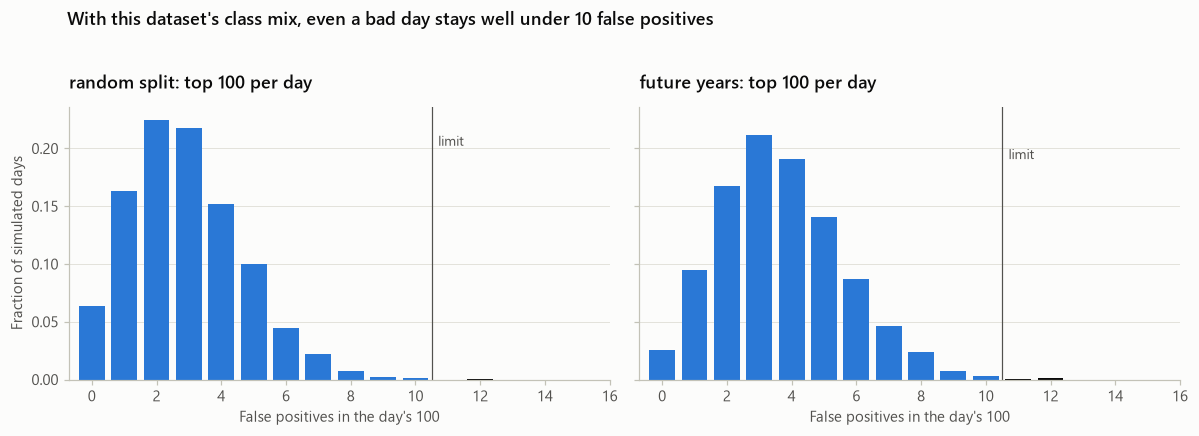

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, name in zip(axes, scenarios):
    counts = daily[(name, "top 100")]["false_positives"].value_counts(normalize=True).sort_index()
    ax.bar(counts.index, counts.values, color=[IA if c <= MAX_FP else INK for c in counts.index], width=0.8)
    ax.axvline(MAX_FP + 0.5, color=INK_2, linewidth=0.8)
    ax.annotate("limit", xy=(MAX_FP + 0.7, counts.max() * 0.9), color=INK_2, fontsize=9)
    ax.set(title=f"{name}: top 100 per day", xlabel="False positives in the day's 100", xlim=(-0.7, 16))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Fraction of simulated days")
fig.suptitle("With this dataset's class mix, even a bad day stays well under 10 false positives",
             x=0.06, y=1.03, ha="left", fontsize=12, fontweight="semibold")
fig.tight_layout()
ztf_style.save(fig, "05_daily_false_positives");

**What it shows:**
* With this dataset's class mix, **simply sending the top 100 meets the limit with room to spare**: about 3–4 false positives on a typical day, 6–7 on the worst 5% of days, and almost never more than 10. That holds even for future years.
* The threshold rule behaves almost identically, because the 95%-precision threshold falls close to the 100th-ranked candidate on a typical day.
* Why is it this easy? About 68% of candidates are Ia, so roughly **226 of each day's 333 are Ia**. The model only needs to pick the clearest 100 of them.

That last point is the catch.

## 3 · The catch: how Ia-rich is the real stream?

Everything above assumes the incoming candidates are as Ia-rich as this dataset's *labelled* objects. They are the objects that **got a spectrum**, and that's not a random sample. Notebook 3 found that the *unclassified* objects are fainter and look different.

The model itself can give a rough estimate. If its probabilities are about right (section 4 checks this), the **average P(Ia) over a group of objects estimates the fraction that are Ia**:

In [7]:
full_model = make_model().fit(X, y)                        # trained on all labelled objects
p_unlabelled = full_model.predict_proba(unlabelled[PHOTOMETRIC])[:, 1]

stream_estimate = (y.sum() + p_unlabelled.sum()) / (len(y) + len(p_unlabelled))
pd.DataFrame({"objects": [len(y), len(p_unlabelled), len(y) + len(p_unlabelled)],
              "Ia fraction": [y.mean(), p_unlabelled.mean(), stream_estimate],
              "how we know": ["spectra (true labels)", "model estimate: mean P(Ia)", "combined"]},
             index=["labelled", "unclassified", "whole stream"]).round(3)

,objects,Ia fraction,how we know
labelled,7832,0.678,spectra (true labels)
unclassified,3040,0.669,model estimate: mean P(Ia)
whole stream,10872,0.675,combined


By this estimate, the unclassified objects are **about as Ia-rich as the labelled ones** (67% vs 68%), so the whole stream would be about 67% Ia. That's good news, but treat it with caution:
* the unclassified objects are fainter than most of the training data, so the model is extrapolating a little;
* the estimate assumes the probabilities are calibrated for the unclassified objects, which can't be checked without their labels;
* a different survey, or a change in which objects get followed up, would change the mix.

So the safe approach is to see how each rule copes **across a range of Ia fractions**.

`draw_day` can control the day's mix: with `ia_fraction` set, it draws that fraction of each day's 333 from the Ia objects and the rest from the non-Ia objects.

In [8]:
fractions = [0.7, 0.6, 0.5, 0.4, 0.3]
name = "future years"                                      # the stricter scenario from here on
rows = []
for f in fractions:
    for rule, policy in [("top 100", top_k()), (f"P(Ia) ≥ {thresholds[name]:.2f}", threshold(thresholds[name]))]:
        rows.append({"Ia fraction": f, "rule": rule,
                     **summarise(simulate_days(proba[name], truth[name], policy, ia_fraction=f, n_days=3000))})
mix = pd.DataFrame(rows)
mix.pivot(index="Ia fraction", columns="rule", values=["sent per day", "FP per day (mean)", "days over the limit"]) \
   .sort_index(ascending=False).round(2)

sent per day         FP per day (mean)          \
rule        P(Ia) ≥ 0.89 top 100      P(Ia) ≥ 0.89 top 100   
Ia fraction                                                  
0.7                99.67   100.0              4.54    4.55   
0.6                96.04   100.0              7.58    7.95   
0.5                85.44   100.0             10.10   13.34   
0.4                72.64   100.0             12.22   21.65   
0.3                59.68   100.0             14.26   34.91   

            days over the limit          
rule               P(Ia) ≥ 0.89 top 100  
Ia fraction                              
0.7                        0.01    0.01  
0.6                        0.14    0.17  
0.5                        0.43    0.78  
0.4                        0.68    1.00  
0.3                        0.85    1.00

**What it shows:**
* **Top 100 collapses as the Ia fraction falls.** At 60% Ia it already breaks the limit on 1 day in 6. At 50% it breaks it on most days (78%), and below that on nearly every day. With fewer Ia arriving, filling all 100 slots means reaching further down the ranking, into the uncertain cases.
* **The threshold rule degrades more gently,** because it sends fewer candidates when fewer clear Ia arrive (73 a day at 40% Ia). But it still breaks the limit often (43% of days at 50% Ia), because a threshold chosen at 68% Ia is too generous when Ia are rarer. The same P(Ia) means less when Ia are rarer; section 4 corrects for this.

So the real question for planning is: **how many can we safely send per day, for a given Ia fraction?** Using the simulated days, find the largest daily top-*k* for which even the worst 5% of days stay within 10 false positives:

Ia fraction,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75
random split,40,48,56,64,73,84,93,100,100,100,100
future years,30,37,43,50,58,68,78,88,100,100,100


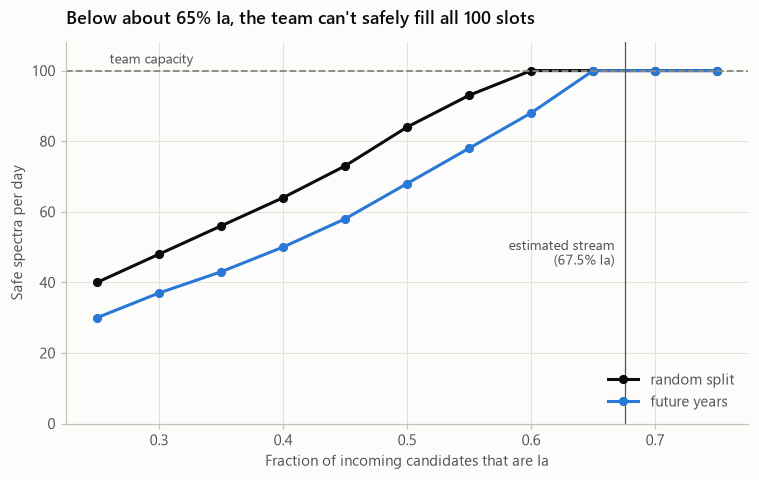

In [9]:
def safe_volume(p, truth, ia_fraction, n_days=3000, seed=0):
    # Largest daily top-k whose worst-5%-of-days false-positive count stays within MAX_FP.
    rng = np.random.default_rng(seed)
    fp_at_k = np.empty((n_days, CAPACITY), dtype=int)
    for d in range(n_days):
        day = draw_day(rng, p, truth, ia_fraction)
        fp_at_k[d] = np.cumsum(truth[day[:CAPACITY]] == 0)     # false positives if we send the top 1, 2, ..., 100
    ok = np.percentile(fp_at_k, 95, axis=0) <= MAX_FP
    return int(np.flatnonzero(ok).max()) + 1 if ok.any() else 0


fine_fractions = np.round(np.arange(0.25, 0.751, 0.05), 2)
safe = pd.DataFrame({name: [safe_volume(proba[name], truth[name], f) for f in fine_fractions] for name in scenarios},
                    index=pd.Index(fine_fractions, name="Ia fraction"))

fig, ax = plt.subplots()
for (name, color) in zip(scenarios, [INK, IA]):
    ax.plot(safe.index, safe[name], color=color, marker="o", markersize=5, label=name)
ax.axhline(CAPACITY, color=MUTED, linewidth=1.2, linestyle="--")
ax.annotate("team capacity", xy=(0.26, CAPACITY + 2), color=INK_2, fontsize=9)
ax.axvline(stream_estimate, color=INK_2, linewidth=0.8)
ax.annotate(f"estimated stream\n({stream_estimate:.1%} Ia)", xy=(stream_estimate - 0.008, 45), ha="right",
            color=INK_2, fontsize=9)
ax.set(xlabel="Fraction of incoming candidates that are Ia", ylabel="Safe spectra per day",
       ylim=(0, 108))
ax.legend(loc="lower right")
ax.set_title("Below about 65% Ia, the team can't safely fill all 100 slots")
ztf_style.save(fig, "05_safe_volume");
safe.T

This chart is the planning tool. Read across from the stream's Ia fraction to get the number of spectra per day that keeps the bad days within the limit.
* On *future years*, the stricter test, all 100 slots can be filled safely only above about **65% Ia**. At 60% the safe number is 88 a day, at 50% it's 68, and at 40% it's 50.
* The *future years* line is lower throughout, because the model is weaker on recent data (notebook 3's drift).
* **The estimated stream (67.5%) sits just above that edge.** The plan works today, but with little margin: a few points' drop in the Ia fraction would make 100 a day unsafe.

**The capacity limit is set by the model's ranking quality and the stream's class mix together.** The only way to fill more slots at the same purity is a better ranking, which in this project means better features (colour, full light curves), not a different algorithm.

## 4 · Sending fewer on purpose: an expected-false-positive budget

A fixed top-*k* needs the Ia fraction to be known in advance. A smarter rule reacts to **each day's own candidates**. If the probabilities are **calibrated** (P(Ia) = 0.8 really means 80% of such objects are Ia), then each candidate contributes **1 − P(Ia)** expected false positives. So:

> work down the day's ranking and stop when the **sum of (1 − P(Ia))** reaches a budget, or at 100.

On a day full of clear Ia, that sends all 100. On a weak day, it sends fewer.

### Step 1: calibrate, and check the calibration

`CalibratedClassifierCV` learns a correction from model scores to true frequencies, using cross-validation inside the training data. `method="isotonic"` allows any increasing correction. Then a **reliability check**: group objects by predicted P(Ia) and compare with the fraction that really are Ia.

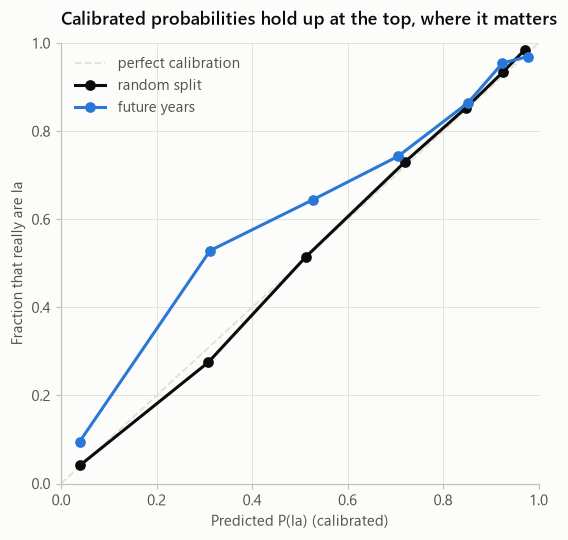

In [10]:
proba_cal = {}
for name, (Xtr, ytr, Xev, _) in scenarios.items():
    calibrated = CalibratedClassifierCV(make_model(), method="isotonic", cv=cv).fit(Xtr, ytr)
    proba_cal[name] = calibrated.predict_proba(Xev)[:, 1]

bins = [0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 1]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=GRID, linewidth=1.2, linestyle="--", label="perfect calibration")
for (name, color) in zip(scenarios, [INK, IA]):
    r = (pd.DataFrame({"p": proba_cal[name], "is_ia": truth[name]})
           .groupby(pd.cut(proba_cal[name], bins), observed=True).mean())
    ax.plot(r["p"], r["is_ia"], color=color, marker="o", markersize=6, label=name)
ax.set(xlabel="Predicted P(Ia) (calibrated)", ylabel="Fraction that really are Ia", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left")
ax.set_title("Calibrated probabilities hold up at the top, where it matters")
ztf_style.save(fig, "05_calibration");

**What it shows:**
* On the random split, the calibrated probabilities follow the diagonal closely.
* On future years, the middle range is *under*confident: more of those objects are Ia than predicted. That's because 2024–2025 has more Ia (73%) than the training years. It's the class-mix effect from section 3, in the other direction.
* At the top, where all the selecting happens, both lines are close to the diagonal. In the top 30% on future years, the predicted false-positive rate is 3.6% and the actual rate is 3.5%.

### Step 2: adjust for the stream's Ia fraction

Calibrated probabilities are correct **for the class mix the model was trained on**. If Ia are rarer in the stream, every P(Ia) is too high. Bayes' rule gives the correction: scale the odds by how much more or less common Ia are now.

$$\text{odds}_\text{new} = \text{odds}_\text{model} \times \frac{\pi_\text{new} / (1-\pi_\text{new})}{\pi_\text{train} / (1-\pi_\text{train})}$$

where π is the Ia fraction. In practice π_new would come from recent spectra, or from the average calibrated P(Ia) of recent candidates as in section 3. Here we give the rule the *true* fraction, which is the best case.

In [11]:
def adjust_to_ia_fraction(p, new_fraction, train_fraction):
    # Bayes' rule, written so that p = 0 and p = 1 stay exactly 0 and 1
    a = p * new_fraction / train_fraction
    b = (1 - p) * (1 - new_fraction) / (1 - train_fraction)
    return a / (a + b)


def fp_budget(budget, cap=CAPACITY):
    # Send the most Ia-like first, until the expected false positives would exceed the budget
    return lambda p_sorted: min(cap, int(np.searchsorted(np.cumsum(1 - p_sorted), budget, side="right")))


train_fraction = scenarios[name][1].mean()
rows = []
for f in fractions:
    p_adj = adjust_to_ia_fraction(proba_cal[name], f, train_fraction)
    for budget in [10, 6]:
        rows.append({"Ia fraction": f, "rule": f"budget {budget} expected FP",
                     **summarise(simulate_days(p_adj, truth[name], fp_budget(budget), ia_fraction=f, n_days=3000))})
    rows.append({"Ia fraction": f, "rule": "safe top-k (from section 3)",
                 **summarise(simulate_days(proba[name], truth[name], top_k(max(safe.loc[f, name], 1)),
                                           ia_fraction=f, n_days=3000))})
budgets = pd.DataFrame(rows)
budgets.pivot(index="Ia fraction", columns="rule", values=["sent per day", "FP per day (mean)", "days over the limit"]) \
       .sort_index(ascending=False).round(2)

sent per day                       \
rule        budget 10 expected FP budget 6 expected FP   
Ia fraction                                              
0.7                        100.00               100.00   
0.6                        100.00                96.69   
0.5                         94.87                77.52   
0.4                         74.73                60.23   
0.3                         56.66                45.07   

                                            FP per day (mean)  \
rule        safe top-k (from section 3) budget 10 expected FP   
Ia fraction                                                     
0.7                               100.0                  4.44   
0.6                                88.0                  7.56   
0.5                                68.0                 11.54   
0.4                                50.0                 11.76   
0.3                                37.0                 12.02   

                                                              \
rule        budget 6 expected FP safe top-k (from section 3)   
Ia fraction                                                    
0.7                         4.44                        4.55   
0.6                         6.93                        6.09   
0.5                         7.59                        6.20   
0.4                         8.12                        6.16   
0.3                         8.50                        6.40   

              days over the limit                       \
rule        budget 10 expected FP budget 6 expected FP   
Ia fraction                                              
0.7                          0.00                 0.00   
0.6                          0.14                 0.08   
0.5                          0.62                 0.13   
0.4                          0.64                 0.18   
0.3                          0.68                 0.22   

                                         
rule        safe top-k (from section 3)  
Ia fraction                              
0.7                                0.01  
0.6                                0.04  
0.5                                0.05  
0.4                                0.04  
0.3                                0.05

**What it shows:**
* **A budget of 10 expected false positives breaks the limit on most days** once Ia are rarer. There are two reasons:
  1. It aims *exactly* at the limit. Even with perfect probabilities, it only controls the *average*, and real days scatter around it, so roughly half would land above 10.
  2. It averages about 12 false positives, not 10. Near the top of the ranking, P(Ia) ≈ 0.97, so each candidate's expected false positive, 1 − P(Ia), is about 0.03. An error of just 0.01 in P(Ia) is then a **30% error** in expected false positives. Calibration that looks excellent on the chart above isn't exact enough for that.
* **A budget of 6 is much safer.** At 30–50% Ia it's over the limit on 13–22% of days, instead of 62–68%. The cost is sending fewer. That's the safety margin again.
* The **safe top-*k*** stays at about 5% of days over the limit by construction, because it was chosen from these very simulations. It needs the Ia fraction to be known in advance. The budget rule adapts to each day automatically but needs a bigger margin. In practice: use the budget rule, size its margin with this kind of simulation, and monitor (section 5).

No rule gets around the main lesson of section 3: when Ia are rarer, **a good rule sends fewer**.

## 5 · Monitoring: noticing when things change

Every rule above rests on assumptions (the class mix, the calibration) that can quietly stop being true. Fortunately, this setup **produces its own labels**: every spectrum the team takes says whether that candidate really was Ia. So the daily false-positive count is known the next day, and can be watched.

A simulated 60 days: the top-100 rule runs on future-years data, and on day 31 the stream's Ia fraction drops from 68% to 45%, as if a new search programme started feeding in fainter, less Ia-rich candidates.

days the alarm (7-day average > 8) fires before the change: 0
first alarm after the change: day 33


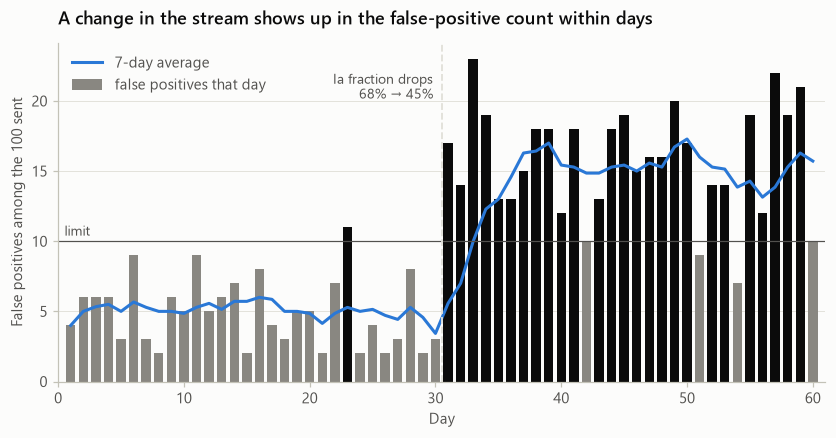

In [12]:
rng = np.random.default_rng(1)
log = []
for day_number in range(1, 61):
    f = 0.68 if day_number <= 30 else 0.45
    day = draw_day(rng, proba[name], truth[name], ia_fraction=f)
    log.append({"day": day_number, "false_positives": int((truth[name][day[:CAPACITY]] == 0).sum())})
log = pd.DataFrame(log).set_index("day")
log["7-day average"] = log["false_positives"].rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(log.index, log["false_positives"], color=[INK if v > MAX_FP else MUTED for v in log["false_positives"]],
       width=0.75, label="false positives that day")
ax.plot(log.index, log["7-day average"], color=IA, label="7-day average")
ax.axhline(MAX_FP, color=INK_2, linewidth=0.8)
ax.axvline(30.5, color=GRID, linewidth=1.2, linestyle="--")
ax.annotate("Ia fraction drops\n68% → 45%", xy=(29.8, log["false_positives"].max() - 1), ha="right", color=INK_2, fontsize=9, va="top")
ax.annotate("limit", xy=(0.5, MAX_FP + 0.4), color=INK_2, fontsize=9)
ax.set(xlabel="Day", ylabel="False positives among the 100 sent", xlim=(0, 61))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("A change in the stream shows up in the false-positive count within days")
ztf_style.save(fig, "05_monitoring");
alarm = log["7-day average"] > 8
print("days the alarm (7-day average > 8) fires before the change:", int(alarm.loc[:30].sum()))
print("first alarm after the change: day", alarm.loc[31:].idxmax())

**What it shows:**
* Days over the limit start immediately after the change, and the 7-day average climbs from about 5 to about 15.
* There is also an isolated bad day *before* the change. Single bad days happen even when nothing is wrong (section 2 found about 1 in 1,000 for future years, so one in 30 is bad luck rather than a sign of trouble). That's why the alarm watches a **7-day average**, not single days.
* An alarm at "7-day average above 8" stays silent for the first 30 days and fires on day 33, three days after the change. The pre-change average reaches about 6, so a threshold of 6 would raise false alarms.

What to do when it fires:
1. **Cut the daily volume** (switch to the budget rule, or use the safe top-*k* chart).
2. **Re-estimate the Ia fraction** from the average calibrated P(Ia) of *all* recent candidates. Don't use the spectra for this: they only cover the top-ranked candidates, so they're far more Ia-rich than the stream.
3. **Recalibrate**, and eventually retrain, on recent labelled data.

## Summary: what I learned

**About decision rules**
* **The model ranks; the decision rule sets precision and volume.** Meeting "≤ 10 false positives in 100 per day" is a question of which rule you put on top of the ranking, not of tuning the model's hyperparameters.
* **Per-day limits need per-day evaluation.** Average precision hides the bad days. Simulate many days and look at the worst 5% of them.
* **Build in a safety margin.** A rule that aims exactly at the limit breaks it on many days. Here, aiming at 95% precision, or a budget of 6 expected false positives instead of 10, kept the bad days within 10.
* **Choose thresholds on training data** (out-of-fold predictions), never on the data used to evaluate them.

**About this scenario**
* With this dataset's class mix (68% Ia), simply sending the **top 100 per day** gives about 96–97% precision, with 6–7 false positives on a bad day. The requirement is met with room to spare, even for future years.
* **The class mix of the real stream is what matters most.** On recent data, all 100 slots are safe only above about 65% Ia. At 50% Ia the safe volume is about 68 a day, and at 40% about 50. The model estimates the stream at about 67.5% Ia, just above that edge.
* **Calibration plus a false-positive budget** adapts the daily volume automatically, but needs a generous margin. At P(Ia) ≈ 0.97, small calibration errors become large errors in the expected false positives, 1 − P(Ia).
* **Monitor the daily false-positive count.** The team's spectra are free labels, and a shift in the stream shows up within days.

## Exercises
1. Change the scenario: the team can take 150 a day with at most 10 false positives. What Ia fraction does the stream need for that to be safe?
2. Replace "at most 10 false positives on 95% of days" with "on 99% of days". How much does the safe volume drop?
3. Use the neural-network ensemble from notebook 4 instead of gradient boosting. Does the safe-volume chart change?
4. In section 5, implement the response: from day 35, estimate the new Ia fraction from the day's average calibrated P(Ia), and switch to the budget rule. How many days over the limit remain?
5. Try `method="sigmoid"` in `CalibratedClassifierCV` (Platt scaling). Is the calibration on future years better or worse than isotonic?